In [2]:
import os
import sys
sys.path.append(os.path.abspath('C:/Users/jhous/Documents/Precise_Modules'))
from Precise import Precise
from boruta_analysis import BorutaAnalyzer
from shap_analysis import SHAPVisualizer
from reinforcement_learning import ReinforcementLearningAnalyzer
from prediction_analysis import PredictionAnalyzer
import numpy as np
import torch_directml
import matplotlib.pyplot as plt
import scanpy as sc


dml = torch_directml.device()
device = dml

In [3]:
adata = sc.read_h5ad("C:/Users/jhous/Downloads/134d34af-cbcd-4837-9310-3d1f83ec6f18.h5ad")

In [4]:
adata.obs

,PMID_donor_id,donor_id,pre_post,author_cell_type,author_cell_type_update,outcome,Combined_outcome,Cancer_type_update,Study_name,Primary_or_met,...,Cell_type_broad,is_primary_data,cell_type,assay,disease,sex,tissue,self_reported_ethnicity,development_stage,observation_joinid
M21_3p2_Lym_A01_S1,35706413gggMEL021,MEL021,Post,T Cell,T_cell,PR,Favourable,MBM,Alvarez_Breckenridge,Metastatic,...,Other,True,T cell,Smart-seq2,metastatic melanoma,male,brain,unknown,postnatal stage,=~lWXS_pj@
M21_3p2_Lym_A02_S2,35706413gggMEL021,MEL021,Post,T Cell,T_cell,PR,Favourable,MBM,Alvarez_Breckenridge,Metastatic,...,Other,True,T cell,Smart-seq2,metastatic melanoma,male,brain,unknown,postnatal stage,oAbeDZ2Hz{
M21_3p2_Lym_A03_S3,35706413gggMEL021,MEL021,Post,T Cell,T_cell,PR,Favourable,MBM,Alvarez_Breckenridge,Metastatic,...,Other,True,T cell,Smart-seq2,metastatic melanoma,male,brain,unknown,postnatal stage,Eq)5a2vT^I
M21_3p2_Lym_A04_S4,35706413gggMEL021,MEL021,Post,T Cell,T_cell,PR,Favourable,MBM,Alvarez_Breckenridge,Metastatic,...,Other,True,T cell,Smart-seq2,metastatic melanoma,male,brain,unknown,postnatal stage,p7MqH^XMcX
M21_3p2_Lym_A05_S5,35706413gggMEL021,MEL021,Post,T Cell,T_cell,PR,Favourable,MBM,Alvarez_Breckenridge,Metastatic,...,Other,True,T cell,Smart-seq2,metastatic melanoma,male,brain,unknown,postnatal stage,@QHyhIcD7i
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
BCC_previous_BCC_bcc.su008.post.tumor.cd45_TCAGCTCAGGTGATAT,31359002gggsu008,su008,Post,NA,Malignant,No,Unfavourable,BCC,Yost,Metastatic,...,Malignant,True,malignant cell,10x 5' transcription profiling,basal cell carcinoma,unknown,arm skin,unknown,postnatal stage,tEZdmy_fhP
BCC_previous_BCC_bcc.su008.post.tumor.cd45_TCCACACGTGTCCTCT,31359002gggsu008,su008,Post,NA,Malignant,No,Unfavourable,BCC,Yost,Metastatic,...,Malignant,True,malignant cell,10x 5' transcription profiling,basal cell carcinoma,unknown,arm skin,unknown,postnatal stage,Xh4gF(0%>O
BCC_previous_BCC_bcc.su008.post.tumor.cd45_TCGGGACTCGGAGGTA,31359002gggsu008,su008,Post,NA,Malignant,No,Unfavourable,BCC,Yost,Metastatic,...,Malignant,True,malignant cell,10x 5' transcription profiling,basal cell carcinoma,unknown,arm skin,unknown,postnatal stage,-s@oa2Bd9*
BCC_previous_BCC_bcc.su008.post.tumor.cd45_TGGCCAGCAATACGCT,31359002gggsu008,su008,Post,NA,Malignant,No,Unfavourable,BCC,Yost,Metastatic,...,Malignant,True,malignant cell,10x 5' transcription profiling,basal cell carcinoma,unknown,arm skin,unknown,postnatal stage,aF~6c0hvIe


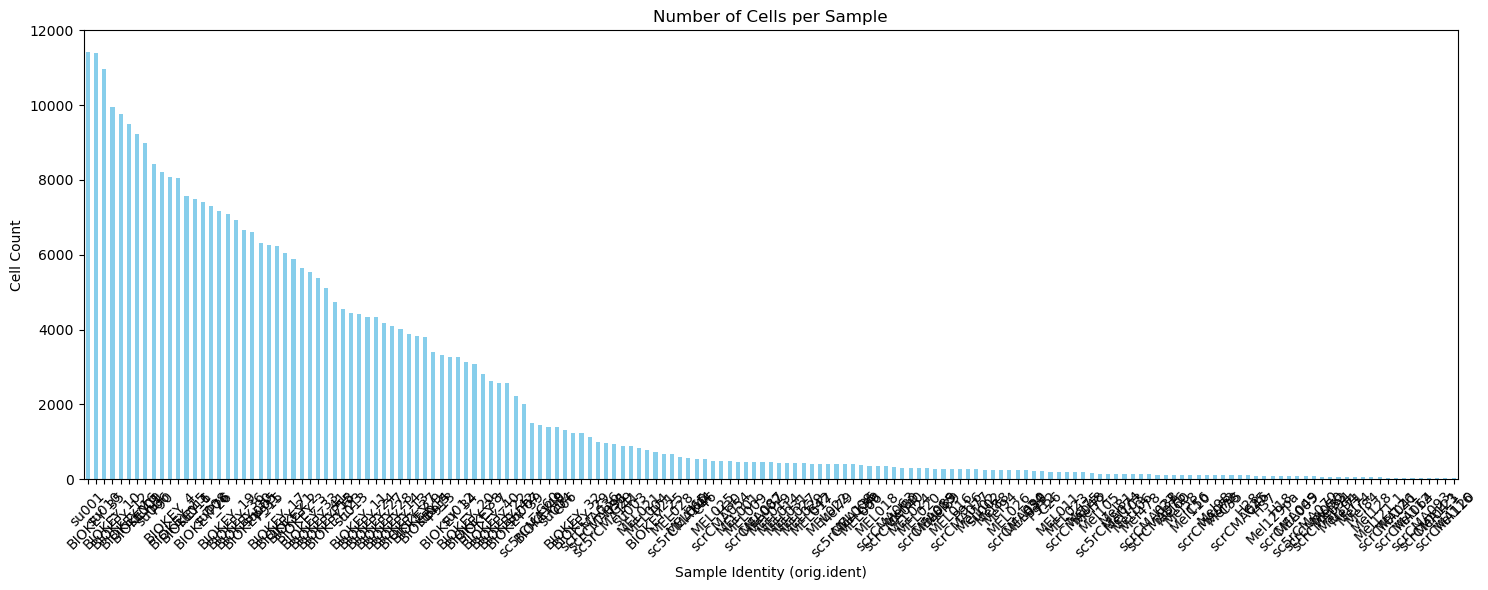

In [7]:
adata.obs
plt.rcParams["figure.figsize"] = (15, 6)
adata.obs['donor_id'].value_counts().plot(kind='bar', color='skyblue')

plt.title('Number of Cells per Sample')
plt.xlabel('Sample Identity')
plt.ylabel('Cell Count')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [19]:
df = adata.obs[['donor_id']].copy()
df['donor_id'] = df['donor_id'].astype(str)
target_string = "BIOKEY"
filtered_df = df[df['donor_id'].str.startswith(target_string)]

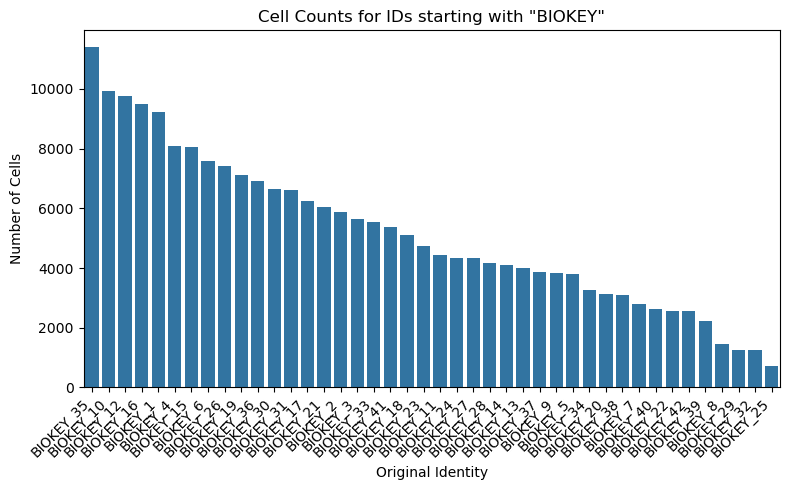

In [20]:
import seaborn as sns
import matplotlib.pyplot as plt
counts = filtered_df['donor_id'].value_counts().reset_index()
counts.columns = ['donor_id', 'cell_count']

# 4. Plot the bar graph
plt.figure(figsize=(8, 5))
sns.barplot(data=counts, x='donor_id', y='cell_count')
plt.xticks(rotation=45, ha='right')
plt.ylabel('Number of Cells')
plt.xlabel('Original Identity')
plt.title(f'Cell Counts for IDs starting with "{target_string}"')
plt.tight_layout()
plt.show()

In [22]:
pre_adata = adata[(adata.obs["pre_post"].astype(str) == "Pre") & (adata.obs["Combined_outcome"].isin(["Unfavourable", "Favourable"]))]

In [23]:
outcome_map =  {
    'Unfavourable': 0,
    'Favourable': 1
}
pre_adata.obs["outcome_encoded"] = pre_adata.obs["Combined_outcome"].map(outcome_map)

print(pre_adata.obs.outcome_encoded.value_counts())

C:\Users\jhous\AppData\Local\Temp\ipykernel_8172\3601719834.py:5: ImplicitModificationWarning: Trying to modify attribute `.obs` of view, initializing view as actual.
  pre_adata.obs["outcome_encoded"] = pre_adata.obs["Combined_outcome"].map(outcome_map)


outcome_encoded
0    77347
1    52291
Name: count, dtype: int64


In [24]:
data_for_filt = pre_adata.obs[['donor_id', 'outcome_encoded']].drop_duplicates()

In [25]:
biokey_filt = data_for_filt[data_for_filt.donor_id.str.contains("BIOKEY")]
biokey_filt.shape

(40, 2)

In [26]:
biokey_adata = pre_adata[pre_adata.obs.donor_id.isin(biokey_filt.donor_id)]
biokey_adata.write_h5ad("biokey_full.h5ad")

In [3]:
biokey_adata = sc.read_h5ad("biokey_full.h5ad")

In [7]:
biokey_adata.obs

,PMID_donor_id,donor_id,pre_post,author_cell_type,author_cell_type_update,outcome,Combined_outcome,Cancer_type_update,Study_name,Primary_or_met,...,is_primary_data,cell_type,assay,disease,sex,tissue,self_reported_ethnicity,development_stage,observation_joinid,outcome_encoded
BIOKEY_10_Pre_AAACCTGAGACGACGT-1,33958794gggBIOKEY_10,BIOKEY_10,Pre,Endothelial_cell,Endothelial,E,Favourable,TNBC,Bassez,Primary,...,True,endothelial cell,10x 5' transcription profiling,triple-negative breast carcinoma,unknown,breast,unknown,middle aged stage,M!SIDeWT0b,1
BIOKEY_10_Pre_AAACCTGCAGGCTGAA-1,33958794gggBIOKEY_10,BIOKEY_10,Pre,Endothelial_cell,Endothelial,E,Favourable,TNBC,Bassez,Primary,...,True,endothelial cell,10x 5' transcription profiling,triple-negative breast carcinoma,unknown,breast,unknown,middle aged stage,*YOaskW6tS,1
BIOKEY_10_Pre_AAACCTGCATCTCGCT-1,33958794gggBIOKEY_10,BIOKEY_10,Pre,T_cell,T_cell,E,Favourable,TNBC,Bassez,Primary,...,True,T cell,10x 5' transcription profiling,triple-negative breast carcinoma,unknown,breast,unknown,middle aged stage,iMN;${6(CZ,1
BIOKEY_10_Pre_AAACCTGGTGCAGTAG-1,33958794gggBIOKEY_10,BIOKEY_10,Pre,Endothelial_cell,Endothelial,E,Favourable,TNBC,Bassez,Primary,...,True,endothelial cell,10x 5' transcription profiling,triple-negative breast carcinoma,unknown,breast,unknown,middle aged stage,AN>fQa)EVK,1
BIOKEY_10_Pre_AAACCTGGTTCTCATT-1,33958794gggBIOKEY_10,BIOKEY_10,Pre,T_cell,T_cell,E,Favourable,TNBC,Bassez,Primary,...,True,T cell,10x 5' transcription profiling,triple-negative breast carcinoma,unknown,breast,unknown,middle aged stage,rz0U2CxGhG,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
Breast_previous_Breast_BIOKEY_42_Pre_TTGAACGGTGATAAGT-1,33958794gggBIOKEY_42,BIOKEY_42,Pre,NA,Malignant,NE,Unfavourable,ER+,Bassez,Primary,...,True,malignant cell,10x 5' transcription profiling,estrogen-receptor positive breast cancer,unknown,breast,unknown,adult stage,FWgq9EAm(Z,0
Breast_previous_Breast_BIOKEY_42_Pre_TTGGAACTCCAGAAGG-1,33958794gggBIOKEY_42,BIOKEY_42,Pre,NA,Malignant,NE,Unfavourable,ER+,Bassez,Primary,...,True,malignant cell,10x 5' transcription profiling,estrogen-receptor positive breast cancer,unknown,breast,unknown,adult stage,?62gfUzlW@,0
Breast_previous_Breast_BIOKEY_42_Pre_TTGGAACTCGGCTTGG-1,33958794gggBIOKEY_42,BIOKEY_42,Pre,NA,Malignant,NE,Unfavourable,ER+,Bassez,Primary,...,True,malignant cell,10x 5' transcription profiling,estrogen-receptor positive breast cancer,unknown,breast,unknown,adult stage,EB|}G^$cr|,0
Breast_previous_Breast_BIOKEY_42_Pre_TTTATGCAGGGATACC-1,33958794gggBIOKEY_42,BIOKEY_42,Pre,NA,Malignant,NE,Unfavourable,ER+,Bassez,Primary,...,True,malignant cell,10x 5' transcription profiling,estrogen-receptor positive breast cancer,unknown,breast,unknown,adult stage,Wo@J3F(W-$,0


In [3]:
biokey_35 = biokey_adata[biokey_adata.obs.donor_id == "BIOKEY_35"]
biokey_35.shape

(7339, 22779)

C:\Users\jhous\anaconda3\envs\scRNA_ML\Lib\site-packages\scanpy\plotting\_utils.py:507: ImplicitModificationWarning: Trying to modify attribute `._uns` of view, initializing view as actual.
  adata.uns[f"{value_to_plot}_colors"] = colors_list


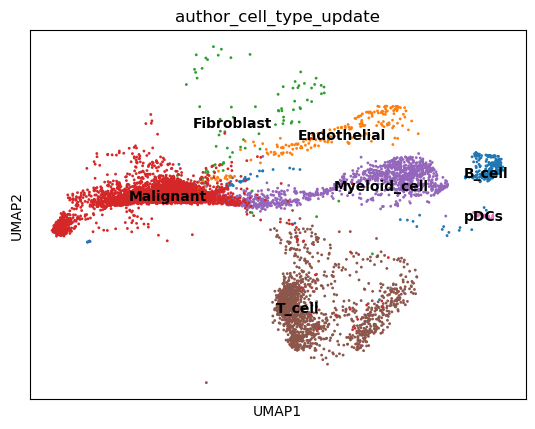

In [4]:
sc.pl.umap(biokey_35, color='author_cell_type_update', legend_loc = 'on data')

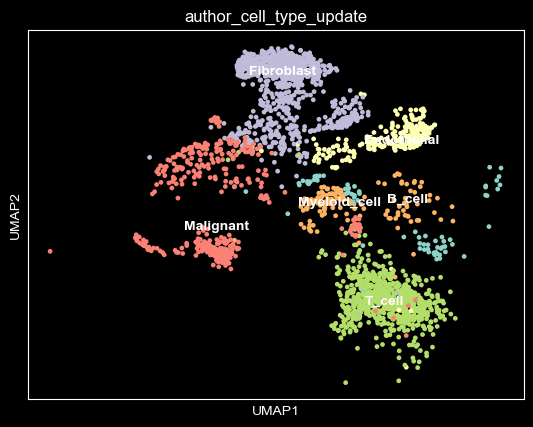

In [9]:
biokey_27 = biokey_adata[biokey_adata.obs.donor_id == "BIOKEY_27"]
sc.pl.umap(biokey_27, color='author_cell_type_update', legend_loc = 'on data')

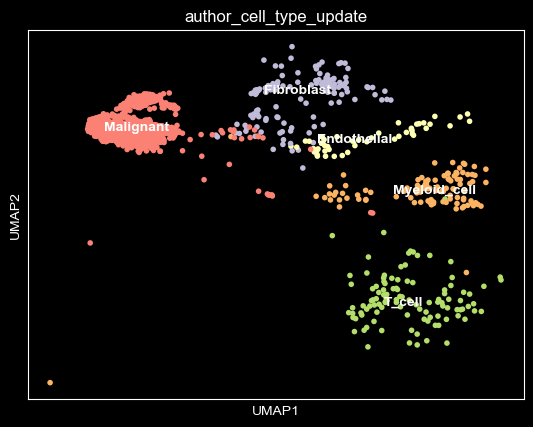

In [11]:
biokey_26 = biokey_adata[biokey_adata.obs.donor_id == "BIOKEY_26"]
sc.pl.umap(biokey_26, color='author_cell_type_update', legend_loc = 'on data')

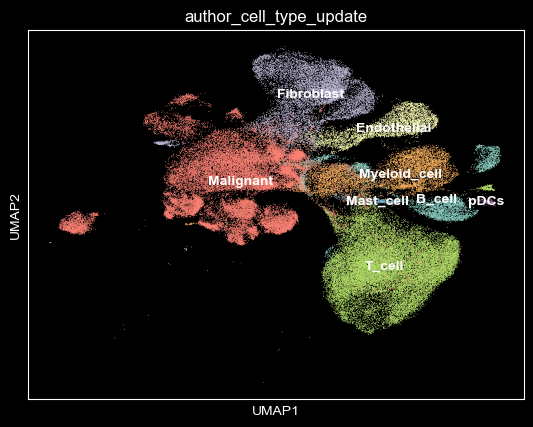

In [5]:
sc.pl.umap(biokey_adata, color='author_cell_type_update', legend_loc = 'on data')

C:\Users\jhous\anaconda3\envs\scRNA_ML\Lib\site-packages\scanpy\plotting\_utils.py:507: ImplicitModificationWarning: Trying to modify attribute `._uns` of view, initializing view as actual.
  adata.uns[f"{value_to_plot}_colors"] = colors_list


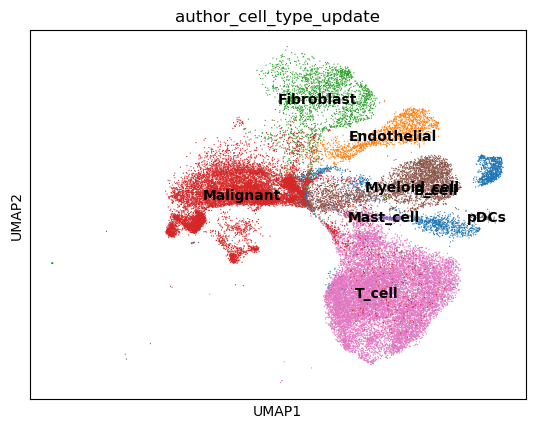

In [5]:
biokey_responder = biokey_adata[biokey_adata.obs.outcome_encoded == 1]
sc.pl.umap(biokey_responder, color='author_cell_type_update', legend_loc = 'on data')

C:\Users\jhous\anaconda3\envs\scRNA_ML\Lib\site-packages\scanpy\plotting\_utils.py:507: ImplicitModificationWarning: Trying to modify attribute `._uns` of view, initializing view as actual.
  adata.uns[f"{value_to_plot}_colors"] = colors_list


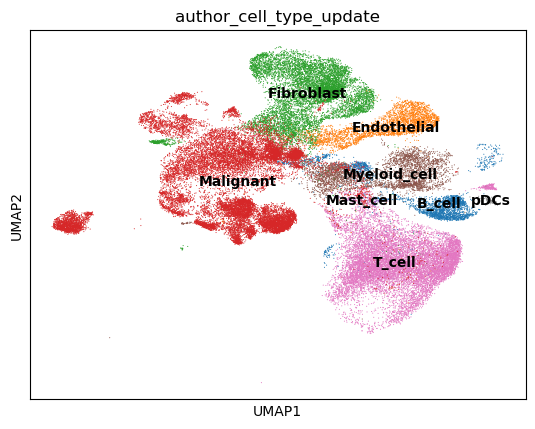

In [6]:
biokey_nonresponder = biokey_adata[biokey_adata.obs.outcome_encoded == 0]
sc.pl.umap(biokey_nonresponder, color='author_cell_type_update', legend_loc = 'on data')

In [7]:
biokey_adata.var_names = biokey_adata.var.feature_name

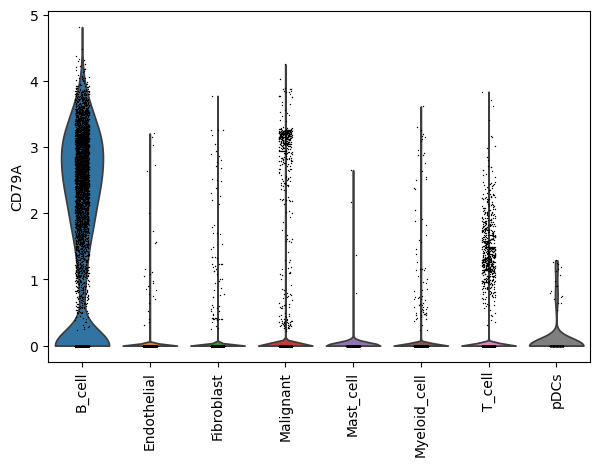

In [8]:
plt.style.use('default')
sc.pl.violin(
    biokey_adata,
    keys='CD79A',
    groupby='author_cell_type_update',
    rotation=90,
    use_raw = False
)

In [10]:
biokey_adata.obs.columns

Index(['PMID_donor_id', 'donor_id', 'pre_post', 'author_cell_type',
       'author_cell_type_update', 'outcome', 'Combined_outcome',
       'Cancer_type_update', 'Study_name', 'Primary_or_met',
       'donor_id_pre_post', 'donor_id_outcome', 'donor_id_cell_types',
       'donor_id_cell_types_pre_post', 'donor_id_pre_post_outcome',
       'tissue_ontology_term_id', 'tissue_type', 'disease_ontology_term_id',
       'cell_type_ontology_term_id', 'PMID', 'Sample',
       'Treatment.or.Mode.of.Action', 'suspension_type',
       'sex_ontology_term_id', 'assay_ontology_term_id',
       'development_stage_ontology_term_id',
       'self_reported_ethnicity_ontology_term_id', 'nCount_RNA',
       'nFeature_RNA', 'Study_name_cancer', 'Cell_type_broad',
       'is_primary_data', 'cell_type', 'assay', 'disease', 'sex', 'tissue',
       'self_reported_ethnicity', 'development_stage', 'observation_joinid',
       'outcome_encoded'],
      dtype='object')

In [4]:
rng = np.random.default_rng(seed=10)
random_integers = rng.integers(low=0, high=biokey_adata.X.shape[0], size=int(np.round(biokey_adata.X.shape[0]/3)))
print(len(random_integers))
biokey_small = biokey_adata[random_integers]
biokey_small.write_h5ad("biokey_small.h5ad")

30395


C:\Users\jhous\anaconda3\envs\scRNA_ML\Lib\site-packages\anndata\_core\anndata.py:1195: ImplicitModificationWarning: Trying to modify attribute `.obs` of view, initializing view as actual.
  df[key] = c
C:\Users\jhous\anaconda3\envs\scRNA_ML\Lib\site-packages\anndata\_core\anndata.py:1811: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  utils.warn_names_duplicates("obs")


In [2]:
biokey_small = sc.read_h5ad("biokey_small.h5ad")

C:\Users\jhous\anaconda3\envs\scRNA_ML\Lib\site-packages\anndata\_core\anndata.py:1811: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  utils.warn_names_duplicates("obs")


In [5]:
biokey_small.obs.rename(columns={'donor_id': 'sample'}, inplace=True)
biokey_small.obs.rename(columns={'outcome_encoded': 'response'}, inplace=True)

In [7]:
output_dir = "C:/Users/jhous/Documents/scRNA_AML_Response_Prediction/biokey_small_paper_run"
precise = Precise(
    biokey_small,
    model_name='XGBoostClassifier',
    output_dir=output_dir,
    target_column="response",  # Adjust based on your dataset
    sample_column="sample"
)
prediction_results = precise.cv_prediction()
sample_results, auc, estimators = prediction_results

C:\Users\jhous\anaconda3\envs\scRNA_ML\Lib\site-packages\anndata\_core\anndata.py:1811: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  utils.warn_names_duplicates("obs")
C:\Users\jhous\anaconda3\envs\scRNA_ML\Lib\site-packages\anndata\_core\anndata.py:1811: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  utils.warn_names_duplicates("obs")


Starting LOO Prediction with 30395 cells and 22779 features.
Sample column: sample, Target column: response.
Using Leave-One-Out cross-validation with 40 splits.

=== Fold 1 ===
Processed 1 samples
Sample	Label	Score
BIOKEY_2	0.0	0.1222

=== Fold 2 ===
Processed 1 samples
Sample	Label	Score
BIOKEY_3	0.0	0.2045

=== Fold 3 ===
Processed 1 samples
Sample	Label	Score
BIOKEY_4	0.0	0.2242

=== Fold 4 ===
Processed 1 samples
Sample	Label	Score
BIOKEY_5	1.0	0.2338

=== Fold 5 ===
Processed 1 samples
Sample	Label	Score
BIOKEY_6	0.0	0.0362

=== Fold 6 ===
Processed 1 samples
Sample	Label	Score
BIOKEY_7	0.0	0.0219

=== Fold 7 ===
Processed 1 samples
Sample	Label	Score
BIOKEY_8	0.0	0.3488

=== Fold 8 ===
Processed 1 samples
Sample	Label	Score
BIOKEY_9	0.0	0.3910

=== Fold 9 ===
Processed 1 samples
Sample	Label	Score
BIOKEY_10	1.0	0.3759

=== Fold 10 ===
Processed 1 samples
Sample	Label	Score
BIOKEY_11	1.0	0.1467

=== Fold 11 ===
Processed 1 samples
Sample	Label	Score
BIOKEY_12	1.0	0.2389

=== Fol

In [8]:
biokey_small.obs.cell_type.value_counts()

cell_type
malignant cell                        11069
T cell                                 9315
fibroblast                             3887
myeloid cell                           2439
B cell                                 1829
endothelial cell                       1633
mast cell                               166
plasmacytoid dendritic cell, human       57
Name: count, dtype: int64